# Comprobación CO₂ v3 · tres theta · modelo actual

Reproduce la formulación principal de `co2_lab016_021_recalibration_v3`: seis LAB, reloj America/Santiago corregido mediante UTC, CO₂ crudo, Hampel centrado, Butterworth adelante–atrás, observaciones de diez minutos y temperatura 20/45.

Se conservan oxígeno, activación por azúcar predicho, trayectorias con/sin nutrición, multiplicador transitorio y reservorio implícito conservativo. La química permanece congelada en cada theta. **Z1 calibra solo la ganancia de observación; Z2 calibra liberación, escala de saturación y ganancia**, igual que la prueba principal v3. Se añade `theta_new` a los dos vectores históricos. Las mezclas positivas exploratorias no se incluyen porque cambian la formulación.

Las funciones específicas de este ensayo están definidas aquí, sin ejecutar ni importar celdas de otro notebook. Las figuras son únicamente inline. Las referencias archivadas se usan para verificar la migración, no como nuevos datos experimentales.

In [1]:
from pathlib import Path
from datetime import datetime
from dataclasses import replace
import sys, json, hashlib, time, re
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display, Markdown, JSON
ROOT=next(p for p in (Path.cwd().resolve(),*Path.cwd().resolve().parents)
          if (p/'data/sources.csv').is_file() and (p/'src/wine_fermentation').is_dir())
if str(ROOT/'src') not in sys.path:sys.path.insert(0,str(ROOT/'src'))
sys.dont_write_bytecode=True
from wine_fermentation import current_model as base
assert Path(sys.prefix).name.lower()=='fermentation',sys.executable
CASES=('theta_full','theta_new','theta_defaults')
COLORS={'theta_full':'#0072B2','theta_new':'#D55E00','theta_defaults':'#009E73'}
STYLES={'theta_full':'-','theta_new':'--','theta_defaults':':'}
plt.style.use('seaborn-v0_8-whitegrid')
plt.rcParams.update({'figure.dpi':100,'font.size':9,'font.family':'DejaVu Sans'})
pd.set_option('display.max_columns',30)
THETAS={name:json.loads((ROOT/f'configs/theta/{name}.json').read_text()) for name in CASES}
assert all(set(theta)==set(base.FULL17) for theta in THETAS.values())
TRACE={'python':sys.executable,'numpy':np.__version__,'pandas':pd.__version__}
START=time.perf_counter()
print('Entorno:',sys.executable)
print('Raíz independiente:',ROOT)


Entorno: D:\anaconda3\envs\fermentation\python.exe
Raíz independiente: D:\claud\Desktop\wine-fermentation


## 1. Funciones de fuente y reservorio: misma implementación principal

In [2]:
from scipy.optimize import least_squares, minimize_scalar
from types import SimpleNamespace
from dataclasses import replace
import math, hashlib, ast
from wine_fermentation import current_co2 as gas
TRAIN=('LAB019','LAB020','LAB021')
HOLDOUT=('LAB016','LAB017','LAB018')
GAS_NAMES=('kCO2_release_h','CO2sat_scale','matrix_gain')
GAS_BOUNDS=((.03,25.),(.35,2.5),(.1,20.))
def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as handle:
        for chunk in iter(lambda: handle.read(1024 * 1024), b""):
            h.update(chunk)
    return h.hexdigest()

def release_forward(c, p, max_step=None):
    """Conservative implicit reservoir, identical to v2 (positive root)."""
    k, scale, gain = (p[n] for n in GAS_NAMES)
    source, dt = c["source"], c["dt"]
    sat = c["sat_base"] * scale
    cd, out = np.zeros(len(source)), np.zeros(len(source))
    for i in range(1, len(source)):
        subdivisions = 1 if max_step is None else int(np.ceil(dt[i-1] / max_step))
        step = dt[i-1] / subdivisions
        inventory, released = cd[i-1], 0.
        for _ in range(subdivisions):
            a = inventory + step * source[i-1]
            aa = 1. + step * k
            b = sat[i] * (1. + .05 * step * k) - a
            root = np.sqrt(b*b + 4.*aa*a*sat[i])
            new = 2.*a*sat[i]/(root+b) if b >= 0. else (root-b)/(2.*aa)
            released += a - new
            inventory = new
        cd[i], out[i] = inventory, released/dt[i-1]
    return gain*out, cd, out

def features(t, y):
    t, y = np.asarray(t), np.asarray(y)
    peak = int(np.argmax(y))
    def run(mask, start=0):
        for i in range(max(2, start), len(t)):
            if mask[i-2:i+1].all() and np.allclose(np.diff(t[i-2:i+1]), 1.):
                return float(t[i])
        return np.nan
    return dict(peak_h=float(t[peak]), peak=float(y[peak]),
                onset_h=run(y >= .05), fall_h=run(y < .05, peak+2))

class Search:
    def prepare(self, name, theta, labs=TRAIN):
        self.theta_by_case[name] = theta.copy()
        for lab in labs:
            if (name, lab) in self.cache:
                continue
            bt = self.batches[lab]
            core = self.gas.integrate_core(bt, theta, bt.time)
            core0 = self.gas.integrate_core(replace(bt, pulses={**bt.pulses, "N": ()}), theta, bt.time)
            core["GF"] = core.G + core.F
            self.cores[name, lab] = core
            time = bt.time
            events = bt.pulses["N"]
            ramp, multiplier = self.histories(time, events, self.old)
            consumed = core.GF.iloc[0]-core.GF.to_numpy()
            z = np.clip((consumed-2.)/8., 0., 1.)
            gate = z*z*(3.-2.*z)
            ini = bt.initials
            oxygen0 = self.old["O2_initial_scale"]*self.cross.co2_model.o2_saturation_mg_l(
                bt.temperature_c[0], ini["E"], ini["G"], ini["F"], 1.)
            ref = self.gas.finish(bt, theta, core, core0, self.old, gate, ramp, multiplier, 0., oxygen0)
            qn, q0 = self.gas.production(theta, bt, core), self.gas.production(theta, bt, core0)
            d = self.obs[self.obs.lab.eq(lab)].sort_values("t_h")
            idx = np.searchsorted(time, d.t_h.to_numpy())-1
            w = (d.t_h.to_numpy()-time[idx]) / (time[idx+1]-time[idx])
            phi = .75**2/(.75**2+ref.O2.to_numpy()**2)
            self.cache[name, lab] = dict(
                time=time, dt=np.diff(time), source=ref.qprod.to_numpy(),
                sat_base=ref.csat.to_numpy()/self.old["CO2sat_scale"],
                qn=qn, q0=q0, ramp=ramp, multiplier=multiplier,
                gate=gate, fferm=.08+.92*phi, obs=d, idx=idx, w=w,
                events=events, core=core, reference=ref, core0_X=core0.X.to_numpy(),
                oxygen0=oxygen0, sugar_consumed=consumed)

    @staticmethod
    def histories(time, events, p):
        ramp = np.clip((time-events[0][0])/p["pulse_t_rise_h"], 0., 1.) if events else np.zeros(len(time))
        mult = np.ones(len(time))
        tr, td = p["tau_rise_h"], p["tau_decay_h"]
        up = tr*np.log1p(td/tr)
        peak = -np.expm1(-up/tr)*np.exp(-up/td)
        for event, dose in events:
            u = np.maximum(time-event, 0.)
            mult += p["A"]*dose/p["N_ref_g_l"]*(-np.expm1(-u/tr))*np.exp(-u/td)/peak
        return ramp, mult

    def source_cache(self, case, lab, p, mode="v2"):
        c = self.cache[case, lab]
        if mode == "v2":
            return c
        ramp, mult = self.histories(c["time"], c["events"], p)
        b = p["pulse_activity_gain"]
        if mode in ("v2_free", "v2_gate"):
            raw = (1.+(b-1.)*ramp)*c["q0"]+ramp*(c["qn"]-c["q0"])
        elif mode in ("positive_mix", "positive_gate"):
            # Nonnegative interpolation: at r=1, source is b*qn, not qn-(1-b)*q0.
            raw = (1.-ramp)*c["q0"]+b*ramp*c["qn"]
        elif mode == "chemical":
            raw = c["qn"]
        else:
            raise ValueError(mode)
        gate = c["gate"]
        if mode in ("v2_gate", "positive_gate"):
            z = np.clip((c["sugar_consumed"]-p["activation_start_g_l"])/p["activation_width_g_l"], 0., 1.)
            gate = z*z*(3.-2.*z)
        # The oxygen parameters remain fixed, but its state follows the changed
        # biomass interpolation when the pulse ramp duration is recalibrated.
        fferm = c["fferm"]
        if not np.array_equal(ramp, c["ramp"]):
            biomass = np.maximum(c["core0_X"]+ramp*(c["core"].X.to_numpy()-c["core0_X"]), 0.)
            oxygen = np.zeros(len(ramp))
            oxygen[0] = c["oxygen0"]
            for i, dt in enumerate(c["dt"]):
                uptake = p["O2_qmax_mg_gdw_h"]*biomass[i]*oxygen[i]/(.25+oxygen[i])
                oxygen[i+1] = max(oxygen[i]-dt*uptake, 0.)
            fferm = .08+.92*.75**2/(.75**2+oxygen**2)
        return {**c, "gate": gate, "source": gate*fferm*mult*np.maximum(raw, 0.)}

    def verify_protected(self):
        assert all(sha256(self.root/p) == h for p, h in self.protected.items())
        return len(self.protected)

## 2. Preparación, reloj y operador de observación v3

In [3]:
import ast

import json

from dataclasses import replace

from pathlib import Path

import numpy as np

import pandas as pd

from numpy.lib.stride_tricks import sliding_window_view

from scipy import signal

from scipy.optimize import least_squares, minimize_scalar

LABS = tuple(f"LAB{i:03}" for i in range(16, 22))

FILTERS = {"offline_20min": 1200., "offline_30min": 1800., "offline_40min": 2400.}

PRIMARY = "offline_30min"

OBS_STEP_H = 1. / 6.

LOD = .05

QUIET = .02

FACTOR = 44.0095 * 60. * .74 / (1000. * 24.16 * 2.)

LOCAL_ZONE = "America/Santiago"

def local_to_utc(values):
    """Interpret logger/worksheet civil times, rejecting ambiguous/invalid times."""
    return pd.DatetimeIndex(pd.to_datetime(values)).tz_localize(
        LOCAL_ZONE, ambiguous="raise", nonexistent="raise").tz_convert("UTC")

def elapsed_civil_hours(hours, origin_local):
    """Convert legacy naive-clock offsets, not actual elapsed durations, to UTC."""
    wall = origin_local + pd.to_timedelta(np.asarray(hours, float), unit="h")
    return (local_to_utc(wall)-local_to_utc([origin_local])[0]).total_seconds()/3600.

def centered_hampel(values, dt_s, window_s=120., k=3.5, floor=.5):
    """Exact median/MAD of the same centered odd window, reflection at edges."""
    x = np.asarray(values, float)
    assert np.isfinite(x).all()
    half = max(1, int(round(window_s / (2. * dt_s))))
    padded = np.pad(x, (half, half), mode="reflect")
    windows = sliding_window_view(padded, 2 * half + 1)
    med = np.median(windows, axis=1)
    mad = np.median(abs(windows - med[:, None]), axis=1)
    flag = abs(x-med) > np.maximum(k * 1.4826 * mad, floor)
    return np.where(flag, med, x), flag

def runs(mask):
    edges = np.diff(np.r_[False, np.asarray(mask, bool), False].astype(int))
    return list(zip(np.flatnonzero(edges == 1), np.flatnonzero(edges == -1)))

def fill_short_gaps(series, max_samples):
    result = series.copy()
    candidate = series.interpolate(method="time", limit_area="inside")
    for a, b in runs(series.isna().to_numpy()):
        if b-a <= max_samples and a > 0 and b < len(series):
            result.iloc[a:b] = candidate.iloc[a:b]
    return result

def butter_sos(tau_s, dt_s, order=3):
    cutoff = 1. / (2. * np.pi * tau_s)
    return signal.butter(order, cutoff, fs=1. / dt_s, output="sos")

def zero_phase(values, tau_s, dt_s):
    # The default SciPy padding is too short for this very low cutoff.
    padlen = min(int(np.ceil(6. * tau_s / dt_s)), len(values)-2)
    assert padlen > 12 and len(values) > 24
    return signal.sosfiltfilt(butter_sos(tau_s, dt_s), values, padtype="odd", padlen=padlen)

def read_window(path, root, columns, start, end=None):
    content = Path(path)
    pieces = []
    for chunk in pd.read_csv(content, usecols=columns, chunksize=400000, low_memory=False):
        stamp = pd.to_datetime(chunk.timestamp, errors="coerce")
        keep = stamp.ge(start)
        if end is not None:
            keep &= stamp.le(end)
        if keep.any():
            part = chunk.loc[keep].copy()
            part["timestamp"] = stamp[keep]
            pieces.append(part)
    if not pieces:
        raise ValueError(f"No data in requested window: {path}")
    return pd.concat(pieces, ignore_index=True), content

class RecalibrationV3(Search):
    def __init__(self, root):
        self.root=Path(root)
        self.base=base
        self.gas=gas
        self.cross=gas.co2_cross
        self.v2=self.root/'data/compatibility/co2_v3'
        settings=json.loads((self.root/'configs/co2_v3_reference.json').read_text(encoding='utf-8'))
        self.old=settings['old_gas_start']
        self.gui=settings['gui']
        assert self.gui==dict(W_SPIKE_SECONDS=120.,K=3.5,MIN_ABS_SPIKE=.5,TAU_SECONDS=1200.,BUTTER_ORDER=3)
        self.thetas={name:json.loads((self.root/f'configs/theta/{name}.json').read_text()) for name in CASES}
        self.initials=pd.read_csv(self.v2/'initial_conditions_v2.csv').set_index('lab')
        self.chem=pd.read_csv(self.v2/'chemistry_v2.csv')
        self.density=pd.read_csv(self.v2/'density_v2.csv')
        self.biomass=pd.read_csv(self.v2/'biomass_v2.csv')
        self.previous_chemistry=pd.DataFrame(columns=['lab','t_h'])
        self.v2_initials=self.initials.copy()
        self.raw_co2,self.raw_temperature,self.t0,self.artifacts={},{},{},{}
        self.dense,self.temperature,self.observations={},{},{}
        self.filter_audit,self.coverage_rows,self.temp_audit=[],[],[]
        self.fit_runs,self.fit_table,self.v3_fits=[],[],{}
        self.saved_core_contexts={}
        self.clock_audit,self.elapsed_audit,self.nutrition_events=[],[],[]
        old_dir=self.root/'data/original/natural/lab016_018'
        book_path=old_dir/'LAB016-018-offline-measurements.xlsx'
        sheet=pd.read_excel(book_path,sheet_name='CondicionesIniciales').set_index('CodigoLab')
        recent_dir=self.root/'data/original/natural/lab019_021'
        recent_t0=pd.Timestamp('2026-09-21 17:00:00')
        recent_co2,_=read_window(recent_dir/'backup_global_co2_completo.csv',self.root,
            ['timestamp','fermentador','flow_sccm','flow_filt_sccm','status'],recent_t0-pd.Timedelta(hours=6))
        recent_temp,_=read_window(recent_dir/'backup_global_temperatura_completo.csv',self.root,
            ['timestamp','fermentador','T','SP','nutricion_activa'],recent_t0-pd.Timedelta(hours=6))
        for i, lab in enumerate(LABS):
            fermenter = f"F{i%3+1}"
            if i < 3:
                row = sheet.loc[lab]
                clock = row.Hora if hasattr(row.Hora, "hour") else pd.to_datetime(str(row.Hora)).time()
                t0 = pd.Timestamp.combine(pd.Timestamp(row.Fecha).date(), clock)
                raw_path = old_dir/f"CO2_F{i+1}_{lab}.csv"
                filt_path = old_dir/f"CO2_FILT_F{i+1}_{lab}.csv"
                temp_path = old_dir/({0:"Temp_F1_LAB016.csv",1:"Temp_F2_LAB017.csv",2:"Temp_F3._LAB018.csv"}[i])
                raw = pd.read_csv(raw_path, parse_dates=["timestamp"])
                recorded = pd.read_csv(filt_path, parse_dates=["timestamp"])
                raw = raw.merge(recorded[["timestamp", "flow_filt_sccm"]], on="timestamp", how="left", validate="one_to_one")
                tmp = pd.read_csv(temp_path, parse_dates=["timestamp"])
            else:
                t0 = recent_t0
                raw = recent_co2[recent_co2.fermentador.eq(fermenter)].copy()
                tmp = recent_temp[recent_temp.fermentador.eq(fermenter)].copy()
            origin_local = t0
            t0 = local_to_utc([origin_local])[0]
            for kind, frame in (("co2", raw), ("temperature", tmp)):
                wall = pd.DatetimeIndex(frame.timestamp)
                utc = local_to_utc(wall)
                local_dt = wall.to_series(index=np.arange(len(wall))).diff().dt.total_seconds().to_numpy()
                real_dt = utc.to_series(index=np.arange(len(utc))).diff().dt.total_seconds().to_numpy()
                jumps = np.flatnonzero(abs(local_dt-real_dt)>1.)
                for j in jumps:
                    self.clock_audit.append(dict(lab=lab,signal=kind,
                        previous_local=str(wall[j-1]),next_local=str(wall[j]),
                        previous_utc=str(utc[j-1]),next_utc=str(utc[j]),
                        civil_interval_seconds=float(local_dt[j]),elapsed_interval_seconds=float(real_dt[j])))
                frame["timestamp_local"] = frame.timestamp.astype(str)
                frame["timestamp"] = utc
            raw = raw[raw.timestamp.ge(t0-pd.Timedelta(hours=6))].sort_values("timestamp").copy()
            tmp = tmp[tmp.timestamp.ge(t0-pd.Timedelta(hours=6))].sort_values("timestamp").copy()
            assert raw.timestamp.is_unique and tmp.timestamp.is_unique
            raw["t_h"] = (raw.timestamp-t0).dt.total_seconds()/3600.
            tmp["t_h"] = (tmp.timestamp-t0).dt.total_seconds()/3600.
            self.t0[lab], self.raw_co2[lab], self.raw_temperature[lab] = t0, raw, tmp
            # Pump activation is nutrition, not evidence of a measurement artifact.
            # Keep its measured response; no bridges, recovery windows or guards.
            self.artifacts[lab] = []
            state = pd.to_numeric(tmp.nutricion_activa, errors="raise").eq(1)
            for a,b in runs(state):
                self.nutrition_events.append(dict(lab=lab,start_h=float(tmp.t_h.iloc[a]),
                    end_h=float(tmp.t_h.iloc[min(b,len(tmp)-1)]),excluded_from_fit=False))
            for name, frame in (("chemistry",self.chem),("density",self.density),
                                ("biomass",self.biomass),("previous_chemistry",self.previous_chemistry)):
                ids = frame.index[frame.lab.eq(lab)]
                if not len(ids):continue
                # t_h=0 may intentionally map a pre-inoculation sample to the
                # initial condition. Preserve that mapping and the measurement.
                old = frame.loc[ids,"t_h"].to_numpy(float)
                if name == "previous_chemistry":
                    # The legacy simulation includes artificial civil-clock
                    # grid points inside the skipped hour; they are not samples.
                    wall = origin_local+pd.to_timedelta(old,unit="h")
                    utc = pd.DatetimeIndex(wall).tz_localize(LOCAL_ZONE,
                        ambiguous="raise",nonexistent="NaT").tz_convert("UTC")
                    exists = ~utc.isna()
                    frame.drop(index=ids[~exists],inplace=True)
                    ids,old,utc = ids[exists],old[exists],utc[exists]
                    new = (utc-t0).total_seconds()/3600.
                else:
                    new = elapsed_civil_hours(old,origin_local)
                frame.loc[ids,"t_h"] = new
                for idx,before,after in zip(ids,old,new):
                    self.elapsed_audit.append(dict(lab=lab,table=name,row=int(idx),
                        civil_t_h=float(before),elapsed_t_h=float(after)))
            old_events = ast.literal_eval(self.initials.loc[lab,"N_events"])
            corrected_events = tuple((float(elapsed_civil_hours([h],origin_local)[0]),dose) for h,dose in old_events)
            self.initials.loc[lab,"N_events"] = repr(corrected_events)
            self.initials.loc[lab,"horizon_h"] = float(elapsed_civil_hours(
                [self.v2_initials.loc[lab,"horizon_h"]],origin_local)[0])

        self.protected={str(p.relative_to(self.root)):sha256(p) for p in self.v2.rglob('*') if p.is_file()}
        for p in (self.root/'configs').rglob('*.json'):
            self.protected[str(p.relative_to(self.root))]=sha256(p)
        self.cores,self.cache,self.theta_by_case={},{},{}
        self.runs=[]


    def process(self):
        for lab in LABS:
            self._process_temperature(lab)
            self._process_co2(lab)
        self.filter_audit = pd.DataFrame(self.filter_audit)
        self.temp_audit = pd.DataFrame(self.temp_audit)
        self._choose_horizons()
        self.coverage = pd.DataFrame(self.coverage_rows)
        # Use the same native ten-minute support for all smoothing sensitivities.
        for lab in LABS:
            dense = self.dense[lab]
            cut = self.horizons[lab]
            width = OBS_STEP_H
            bin_id = np.floor(dense.time_h/width+1e-10).astype(int)
            frame = dense.copy()
            valid = frame.valid_for_fit & frame.time_h.ge(0.) & frame.time_h.le(cut)
            frame["bin"] = bin_id
            agg = frame[valid].groupby("bin").agg(lo=("time_h", "min"),hi=("time_h", "max"),n=("time_h", "size"))
            dt = self.filter_blocks[lab][0]
            keep = (agg.hi-agg.lo >= .75*width) & agg.n.ge(.75*width*3600./dt) & (agg.index*width >= 0.) & ((agg.index+1)*width <= cut+1e-9)
            for a,b in self.fit_exclusions[lab]:
                keep &= ~((agg.index*width <= b)&((agg.index+1)*width >= a))
            bins = agg[keep].index
            for name in FILTERS:
                grouped = frame[valid].groupby("bin")[name].median().reindex(bins)
                points = pd.DataFrame(dict(lab=lab,bin=bins,t_h=(bins+.5)*width,y=grouped.to_numpy()))
                assert points.y.notna().all() and points.t_h.is_unique
                self.observations[name,lab] = points
        self.obs = pd.concat([self.observations[PRIMARY,lab] for lab in LABS],ignore_index=True)
        self.configure_temperature("reference_20_45")

    def _process_temperature(self, lab):
        raw = self.raw_temperature[lab]
        minute = raw.set_index("timestamp")[["T", "SP"]].resample("1min").median()
        minute["T"] = fill_short_gaps(minute["T"], 2)
        result = pd.DataFrame(index=minute.index)
        result["raw_1min"] = minute["T"]
        for name, med, mean in (("reference_20_45", "20min", "45min"), ("strong_30_60", "30min", "60min")):
            result[name] = np.nan
            for a,b in runs(minute["T"].notna()):
                segment = minute["T"].iloc[a:b]
                filtered = segment.rolling(med,center=True,min_periods=1).median().rolling(mean,center=True,min_periods=1).mean()
                result.iloc[a:b,result.columns.get_loc(name)] = filtered.to_numpy()
            valid = result[name].notna() & result.raw_1min.notna()
            self.temp_audit.append(dict(lab=lab,variant=name,raw_std_C=float(result.loc[valid,"raw_1min"].std()),
                filtered_std_C=float(result.loc[valid,name].std()),mean_change_C=float((result.loc[valid,name]-result.loc[valid,"raw_1min"]).mean()),
                max_change_C=float(abs(result.loc[valid,name]-result.loc[valid,"raw_1min"]).max())))
        result["SP"] = minute.SP
        result["time_h"] = (result.index-self.t0[lab]).total_seconds()/3600.
        self.temperature[lab] = result

    def _process_co2(self, lab):
        raw = self.raw_co2[lab]
        dt = float(raw.timestamp.diff().dt.total_seconds().median())
        assert 5. <= dt <= 30., (lab,dt)
        series = raw.set_index("timestamp")[["flow_sccm", "flow_filt_sccm"]].resample(pd.Timedelta(seconds=dt)).median()
        series.index += pd.Timedelta(seconds=dt/2.)
        series["flow_sccm"] = fill_short_gaps(series.flow_sccm, int(60./dt))
        time = (series.index-self.t0[lab]).total_seconds().to_numpy()/3600.
        clean = series.flow_sccm.copy()
        frame = pd.DataFrame(dict(time_h=time,raw_sccm=series.flow_sccm.to_numpy(),
            recorded_sccm=series.flow_filt_sccm.to_numpy(),clean_sccm=clean.to_numpy()),index=series.index)
        frame["despiked_sccm"],frame["hampel_spike"] = np.nan,False
        blocks = [(a,b) for a,b in runs(clean.notna()) if b-a > 100]
        for name in FILTERS:
            frame[name] = np.nan
        for a,b in blocks:
            despiked, flag = centered_hampel(clean.iloc[a:b].to_numpy(), dt)
            frame.iloc[a:b,frame.columns.get_loc("despiked_sccm")] = despiked
            frame.iloc[a:b,frame.columns.get_loc("hampel_spike")] = flag
            for name,tau in FILTERS.items():
                frame.iloc[a:b,frame.columns.get_loc(name)] = zero_phase(despiked,tau,dt)
        # One sensor-zero estimate, from the same raw-derived despiked baseline,
        # is shared by every smoothing variant. Nothing is subtracted from chemistry.
        baseline = (time >= 2.5) & (time <= 12.) & frame.despiked_sccm.notna().to_numpy()
        for event in self.artifacts[lab]:
            baseline &= ~((time >= event["start_h"]) & (time <= event["end_h"]))
        assert baseline.sum() > 20, lab
        zero = max(0.,float(frame.loc[baseline,"despiked_sccm"].quantile(.1)))
        self.fit_exclusions = getattr(self,"fit_exclusions",{})
        # Padding is a numerical extension only, never a fit exclusion margin.
        guard = 0.
        exclusions = []
        self.fit_exclusions[lab] = exclusions
        valid = frame[PRIMARY].notna().to_numpy()
        for name,tau in FILTERS.items():
            uncorrected = frame[name].to_numpy().copy()
            frame[name] = np.maximum(uncorrected-zero,0.)*FACTOR
            use = valid & (time >= 0.)
            peak = int(np.nanargmax(np.where(use,frame[name],np.nan)))
            self.filter_audit.append(dict(lab=lab,variant=name,tau_s=tau,order=3,passes=2,
                raw_dt_s=dt,zero_sccm=zero,n_raw=len(raw),n_grid=len(frame),
                n_hampel=int(frame.hampel_spike.sum()),n_fit_dense=int(use.sum()),
                peak_g_l_h=float(frame[name].iloc[peak]),peak_h=float(time[peak]),
                negative_before_clipping_fraction=float(np.nanmean(uncorrected < zero)),
                data_start_h=float(time[0]),data_end_h=float(time[-1]),guard_h=guard))
        frame["despiked"] = np.maximum(frame.despiked_sccm-zero,0.)*FACTOR
        frame["recorded"] = np.maximum(frame.recorded_sccm-float(pd.read_csv(self.v2/"sensor_audit.csv").set_index("lab").loc[lab,"zero_sccm"]),0.)*FACTOR
        frame["valid_for_fit"] = valid
        self.dense[lab] = frame
        self.filter_blocks = getattr(self,"filter_blocks",{})
        self.filter_blocks[lab] = (dt, blocks)

    def _choose_horizons(self):
        self.horizons = {}
        for lab in LABS:
            dense = self.dense[lab]
            time = dense.time_h.to_numpy()
            if lab in LABS[3:]:
                last_chem = float(self.chem[self.chem.lab.eq(lab)&~self.chem.is_NUT].t_h.max())
            else:
                last_chem = float(max(self.density[self.density.lab.eq(lab)].t_h.max(),
                                      self.biomass[self.biomass.lab.eq(lab)].t_h.max()))
            # Horizon is fixed by the primary observation preprocessing, never
            # by a fitted model. Any unresolved ending is explicitly censored.
            frame = dense[dense.time_h.ge(0.)&dense.valid_for_fit].copy()
            frame["bin"] = np.floor(frame.time_h/OBS_STEP_H).astype(int)
            ten = frame.groupby("bin")[PRIMARY].median()
            tt = (ten.index.to_numpy()+.5)*OBS_STEP_H
            last_active = float(tt[ten.to_numpy() >= LOD][-1]) if (ten>=LOD).any() else 0.
            quiet_end = np.nan
            for i in range(len(ten)-11):
                chunk = ten.iloc[i:i+12]
                if tt[i] >= last_active and np.all(np.diff(chunk.index)==1) and chunk.le(QUIET).all():
                    quiet_end = float((chunk.index[-1]+1)*OBS_STEP_H)
                    break
            available = min(float(dense.time_h.max()),float(self.raw_temperature[lab].t_h.max()))
            requested = max(last_chem,quiet_end) if np.isfinite(quiet_end) else available
            cut = min(requested,available)
            assert last_chem <= available+1e-6, (lab,last_chem,available)
            self.horizons[lab] = cut
            self.coverage_rows.append(dict(lab=lab,last_chemical_or_offline_h=last_chem,
                previous_v2_end_h=float(self.v2_initials.loc[lab,"horizon_h"]),
                raw_co2_end_h=float(self.raw_co2[lab].t_h.max()),raw_temperature_end_h=float(self.raw_temperature[lab].t_h.max()),
                last_detectable_CO2_h=last_active,quiet_confirmed_h=quiet_end,cut_h=cut,
                quiet_threshold_g_l_h=QUIET,quiet_duration_h=2.,
                right_censored=not np.isfinite(quiet_end),chemistry_covered=last_chem<=cut+1e-8))

    def configure_temperature(self, variant):
        self.cores,self.cache,self.theta_by_case = {},{},{}
        self.batches = {}
        for lab in LABS:
            # Integrate beyond the reported cutoff, using actual remaining
            # temperature, so the zero-phase observation operator has context.
            available = min(float(self.dense[lab].time_h.max()),float(self.raw_temperature[lab].t_h.max()))
            horizon = available
            events = ast.literal_eval(self.initials.loc[lab,"N_events"])
            grid = np.unique(np.r_[np.arange(0.,horizon,1./12.),horizon,[t for t,_ in events]])
            temp = self.temperature[lab].dropna(subset=[variant])
            assert temp.time_h.min() <= 0. and horizon-temp.time_h.max() <= 1./60.+1e-8
            row = self.v2_initials.loc[lab]
            self.batches[lab] = self.base.BatchData(medium="natural",batch=lab,time=grid,
                temperature_c=np.interp(grid,temp.time_h,temp[variant]),
                initials={s:float(row[s]) for s in self.base.STATE_NAMES},
                pulses={**{s:() for s in self.base.INPUT_CHANNELS},"N":events},
                observations={s:np.full(len(grid),np.nan) for s in self.base.STATE_NAMES})
        self.temperature_variant = variant

    def prepare_all(self):
        for case,key in ((name,name) for name in CASES):
            self.prepare(case,self.thetas[key],LABS)
        self.saved_core_contexts[self.temperature_variant] = (self.batches,self.cores,self.cache,self.theta_by_case)

    def set_context(self, name):
        self.batches,self.cores,self.cache,self.theta_by_case = self.saved_core_contexts[name]
        self.temperature_variant = name

    def observed_prediction(self, case, lab, params, filtering=PRIMARY, mode="v2", max_step=None):
        cache = self.source_cache(case,lab,params,mode)
        physical,cd,qout = release_forward(cache,params,max_step=max_step)
        dense = self.dense[lab]
        t = dense.time_h.to_numpy()
        native = np.interp(t,cache["time"],physical,left=0.)
        filtered = np.full(len(t),np.nan)
        dt,blocks = self.filter_blocks[lab]
        for a,b in blocks:
            filtered[a:b] = np.maximum(zero_phase(native[a:b],FILTERS[filtering],dt),0.)
        return filtered,physical,cd,qout

    def v3_residual(self, params, case, labs, filtering=PRIMARY, mode="v2"):
        parts = []
        for lab in labs:
            pred = self.observed_prediction(case,lab,params,filtering,mode)[0]
            obs = self.observations[filtering,lab]
            p = np.interp(obs.t_h,self.dense[lab].time_h,pred)
            y = obs.y.to_numpy()
            error = np.where(y>=LOD,p-y,np.maximum(p-LOD,0.))
            assert np.isfinite(error).all(), (case,lab,filtering)
            parts.append(error/np.sqrt(len(error)))
        return np.concatenate(parts)

    def fit_layer(self, case, labs, label, filtering=PRIMARY, mode="v2", starts=3, max_nfev=180):
        labs = tuple(labs)
        def scalar_objective(logg):
            r = self.v3_residual({**self.old,"matrix_gain":float(np.exp(logg))},case,labs,filtering,mode)
            return r@r
        scalar = minimize_scalar(scalar_objective,bounds=np.log(GAS_BOUNDS[2]),method="bounded",options={"xatol":1e-8})
        z1 = {**self.old,"matrix_gain":float(np.exp(scalar.x))}
        extra = ("pulse_activity_gain","pulse_t_rise_h") if mode=="positive_mix" else ()
        names = GAS_NAMES+extra
        bounds = GAS_BOUNDS+((.05,1.5),(6.,120.)) if extra else GAS_BOUNDS
        lo,hi = np.log(np.array(bounds).T)
        seeds = [z1,{**z1,"kCO2_release_h":2.,"CO2sat_scale":1.},
                 {**z1,"kCO2_release_h":.15,"CO2sat_scale":2.4}][:starts]
        solutions = []
        for i,seed in enumerate(seeds):
            def fun(x):
                params = {**self.old,**dict(zip(names,np.exp(x)))}
                return self.v3_residual(params,case,labs,filtering,mode)
            sol = least_squares(fun,np.clip(np.log([seed[p] for p in names]),lo+1e-9,hi-1e-9),
                bounds=(lo,hi),max_nfev=max_nfev,ftol=1e-7,xtol=1e-7,gtol=1e-7)
            solutions.append(sol)
            self.fit_runs.append(dict(theta=case,training=label,filtering=filtering,mode=mode,
                temperature=self.temperature_variant,start=i,success=bool(sol.success),nfev=sol.nfev,
                objective=float(sol.fun@sol.fun),message=sol.message))
        best = min(solutions,key=lambda s:s.fun@s.fun)
        z2 = {**self.old,**dict(zip(names,np.exp(best.x)))}
        singular = np.linalg.svd(best.jac,compute_uv=False)
        assert best.fun@best.fun <= scalar.fun+1e-6
        for stage,p,success,obj in (("Z1",z1,scalar.success,scalar.fun),("Z2",z2,best.success,best.fun@best.fun)):
            key = (self.temperature_variant,filtering,mode,case,label,stage)
            self.v3_fits[key] = p
            self.fit_table.append(dict(temperature=self.temperature_variant,filtering=filtering,mode=mode,
                theta=case,training=label,labs=",".join(labs),stage=stage,success=bool(success),objective=float(obj),
                jacobian_ratio=float(singular[-1]/singular[0]) if stage=="Z2" else np.nan,
                active_bounds=",".join(n for n,x,a,b in zip(names,best.x,lo,hi) if min(x-a,b-x)<.005) if stage=="Z2" else "",
                **{n:p[n] for n in names}))
        print(self.temperature_variant,filtering,mode,case,label,"Z1/Z2",round(float(scalar.fun),6),round(float(best.fun@best.fun),6),flush=True)
        return z1,z2

    def curve_v3(self, case, lab, params, filtering=PRIMARY, mode="v2"):
        observed,physical,cd,qout = self.observed_prediction(case,lab,params,filtering,mode)
        cache = self.source_cache(case,lab,params,mode)
        t = cache["time"]
        return pd.DataFrame(dict(t_h=t,CO2_physical=physical,CO2_observed_operator=np.interp(t,self.dense[lab].time_h,observed),
            Cd=cd,qgas=qout,qprod=cache["source"],gate=cache["gate"],
            temperature_C=self.batches[lab].temperature_c))

    def metrics_v3(self, case, params, labs, filtering=PRIMARY, mode="v2", common_target=False):
        rows = []
        for lab in labs:
            pred = self.observed_prediction(case,lab,params,filtering,mode)[0]
            obs = self.observations[filtering,lab]
            p = np.interp(obs.t_h,self.dense[lab].time_h,pred)
            y = obs.y.to_numpy()
            if common_target:
                # Despiked raw native signal is the same reference for all filters.
                rawp = self.curve_v3(case,lab,params,filtering,mode)
                p = np.interp(obs.t_h,rawp.t_h,rawp.CO2_physical)
                d = self.dense[lab]
                bins = np.floor(d.time_h/OBS_STEP_H+1e-10).astype(int)
                y = d.groupby(bins).despiked.median().reindex(obs.bin).to_numpy()
            error = p-y
            after_peak = obs.t_h.to_numpy()>=float(obs.t_h.iloc[int(np.argmax(y))])
            for window,mask in (("all",np.ones(len(obs),bool)),("after_peak",after_peak),("after_100h",obs.t_h.to_numpy()>=100.)):
                if not mask.any():
                    continue
                rows.append(dict(theta=case,lab=lab,window=window,n=int(mask.sum()),
                    RMSE=float(np.sqrt(np.mean(error[mask]**2))),MAE=float(np.mean(abs(error[mask]))),
                    bias=float(error[mask].mean()),peak=float(p.max()),observed_peak=float(y.max()),
                    peak_h=float(obs.t_h.iloc[int(np.argmax(p))]),target="despiked_raw_common" if common_target else "same_offline_operator"))
        return pd.DataFrame(rows)

    def chemistry_v3(self, case):
        rows = []
        for lab in LABS[3:]:
            core = self.cores[case,lab]
            data = self.chem[self.chem.lab.eq(lab)&~self.chem.is_NUT&self.chem.t_h.gt(0.)]
            for channel,column,mult in (("N","YAN_mg_l",1000.),("G","G_g_l",1.),("F","F_g_l",1.),("GF","GF_g_l",1.),("E","E_g_l",1.)):
                points = data[["t_h",column]].dropna()
                e = np.interp(points.t_h,core.index,core[channel]*mult)-points[column].to_numpy()
                rows.append(dict(temperature=self.temperature_variant,theta=case,lab=lab,channel=channel,
                    n=len(points),RMSE=float(np.sqrt(np.mean(e**2))),bias=float(e.mean())))
        return pd.DataFrame(rows)

## 3. Reconstrucción desde los datos completos copiados

In [4]:
OUT=ROOT/'results/compatibility_co2_v3';OUT.mkdir(parents=True,exist_ok=True)
V=RecalibrationV3(ROOT)
V.process()
display(V.coverage)
display(pd.DataFrame(V.clock_audit))
V.coverage.to_csv(OUT/'coverage.csv',index=False)
V.filter_audit.to_csv(OUT/'filter_audit.csv',index=False)
V.initials.reset_index().to_csv(OUT/'initial_conditions_corrected_clock.csv',index=False)
pd.DataFrame(V.clock_audit).to_csv(OUT/'clock_change_audit.csv',index=False)
assert len(V.clock_audit)==6
assert (local_to_utc(['2026-09-06 01:00:01'])[0]-local_to_utc(['2026-09-05 23:59:47'])[0]).total_seconds()==14.
for lab in LABS:assert not V.fit_exclusions[lab] and not V.artifacts[lab]
reference_obs=pd.read_csv(ROOT/'data/compatibility/co2_v3/reference/observations_10min.csv')
current_obs=pd.concat([frame.assign(filtering=filtering) for (filtering,lab),frame in V.observations.items()],ignore_index=True)
joined=current_obs.merge(reference_obs,on=['lab','filtering','bin'],suffixes=('_new','_ref'),validate='one_to_one')
assert len(joined)==len(reference_obs)==len(current_obs)
preprocess_error=float(np.max(abs(joined.y_new-joined.y_ref)))
time_error=float(np.max(abs(joined.t_h_new-joined.t_h_ref)))
assert preprocess_error<1e-10 and time_error<1e-10
print('Paridad observaciones v3:',len(joined),'filas; error máximo',preprocess_error)
current_obs.to_csv(OUT/'observations_10min.csv',index=False)
display(V.filter_audit.query('variant == @PRIMARY').round(6))


,lab,last_chemical_or_offline_h,previous_v2_end_h,raw_co2_end_h,raw_temperature_end_h,last_detectable_CO2_h,quiet_confirmed_h,cut_h,quiet_threshold_g_l_h,quiet_duration_h,right_censored,chemistry_covered
0,LAB016,56.184722,152.100278,151.100278,151.100000,151.083333,NaN,151.100000,0.02,2.0,True,True
1,LAB017,56.183333,152.098889,151.098889,151.098611,124.583333,141.000000,141.000000,0.02,2.0,False,True
2,LAB018,56.181389,152.096944,151.096944,151.096944,134.416667,141.000000,141.000000,0.02,2.0,False,True
3,LAB019,166.000000,166.000000,183.082222,183.085833,131.750000,144.500000,166.000000,0.02,2.0,False,True
4,LAB020,166.000000,166.000000,183.082222,183.085000,147.250000,172.333333,172.333333,0.02,2.0,False,True
5,LAB021,166.000000,166.000000,183.082222,183.085278,97.916667,111.833333,166.000000,0.02,2.0,False,True


,lab,signal,previous_local,next_local,previous_utc,next_utc,civil_interval_seconds,elapsed_interval_seconds
0,LAB016,co2,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0
1,LAB016,temperature,2026-09-05 23:59:59,2026-09-06 01:00:13,2026-09-06 03:59:59+00:00,2026-09-06 04:00:13+00:00,3614.0,14.0
2,LAB017,co2,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0
3,LAB017,temperature,2026-09-05 23:59:46,2026-09-06 01:00:00,2026-09-06 03:59:46+00:00,2026-09-06 04:00:00+00:00,3614.0,14.0
4,LAB018,co2,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0
5,LAB018,temperature,2026-09-05 23:59:47,2026-09-06 01:00:01,2026-09-06 03:59:47+00:00,2026-09-06 04:00:01+00:00,3614.0,14.0


Paridad observaciones v3: 16872 filas; error máximo 1.1102230246251565e-16


,lab,variant,tau_s,order,passes,raw_dt_s,zero_sccm,n_raw,n_grid,n_hampel,n_fit_dense,peak_g_l_h,peak_h,negative_before_clipping_fraction,data_start_h,data_end_h,guard_h
1,LAB016,offline_30min,1800.0,3,2,11.0,0.0,47513,51416,220,49452,0.771951,46.531528,0.010075,-5.999583,151.101806,0.0
4,LAB017,offline_30min,1800.0,3,2,11.0,0.0,47512,51415,260,49452,0.850792,62.296806,0.003793,-5.997917,151.100417,0.0
7,LAB018,offline_30min,1800.0,3,2,11.0,0.0,47512,51415,226,49451,0.798440,43.903472,0.004240,-5.999861,151.098472,0.0
10,LAB019,offline_30min,1800.0,3,2,10.0,0.0,65157,67763,177,65910,0.693821,70.193056,0.000000,-5.145833,183.081944,0.0
13,LAB020,offline_30min,1800.0,3,2,10.0,0.0,65158,67764,156,65910,0.509603,80.320833,0.009636,-5.148611,183.081944,0.0
16,LAB021,offline_30min,1800.0,3,2,10.0,0.0,65158,67764,238,65910,0.969782,52.201389,0.000148,-5.148611,183.081944,0.0


## 4. Química congelada y paridad con las trayectorias v3 archivadas

In [5]:
V.prepare_all()
refchem=pd.read_csv(ROOT/'data/compatibility/co2_v3/reference/chemistry_trajectories.csv',float_precision='round_trip')
parity=[];cores=[]
for case in CASES:
    for lab in LABS:
        cr=V.cores[case,lab];cores.append(cr[cr.index<=V.horizons[lab]].rename_axis('t_h').reset_index().assign(theta=case,lab=lab))
        if case in ('theta_full','theta_defaults'):
            target=refchem[refchem.theta.eq(case)&refchem.lab.eq(lab)].sort_values('t_h')
            prediction=np.column_stack([np.interp(target.t_h,cr.index,cr[state]) for state in base.STATE_NAMES])
            error=float(np.max(abs(prediction-target[list(base.STATE_NAMES)].to_numpy())))
            assert error<2e-6,(case,lab,error)
            parity.append(dict(theta=case,lab=lab,chemical_max_abs=error))
chemistry=pd.concat([V.chemistry_v3(case) for case in CASES],ignore_index=True)
chemistry.to_csv(OUT/'chemistry_metrics.csv',index=False)
pd.concat(cores,ignore_index=True).to_csv(OUT/'chemistry_trajectories.csv',index=False)
display(pd.DataFrame(parity));display(chemistry.pivot_table(index=['lab','channel'],columns='theta',values='RMSE').round(4))


,theta,lab,chemical_max_abs
0,theta_full,LAB016,1.776357e-14
1,theta_full,LAB017,3.025358e-14
2,theta_full,LAB018,1.776357e-14
3,theta_full,LAB019,1.421085e-14
4,theta_full,LAB020,1.421085e-14
5,theta_full,LAB021,1.421085e-14
6,theta_defaults,LAB016,1.421085e-14
7,theta_defaults,LAB017,3.014256e-14
8,theta_defaults,LAB018,1.421085e-14
9,theta_defaults,LAB019,1.421085e-14


theta           theta_defaults  theta_full  theta_new
lab    channel                                       
LAB019 E                8.1077      5.2274    12.3826
       F               13.8169      6.2486     3.6270
       G                8.8671      7.4546     2.6697
       GF              19.8592     11.4311     6.8143
       N               58.7703     57.5017    46.2415
LAB020 E               12.7855      4.3602     4.5903
       F                9.5374      6.2198     5.1670
       G               11.2267     10.4820     8.2707
       GF              20.9980     12.8347     8.7027
       N               19.2804     17.7493     9.5663
LAB021 E               21.5655     13.3876     7.0739
       F               23.9848     17.1860    14.9962
       G               23.8081     22.1530    18.5015
       GF              42.1830     33.7321    31.2786
       N                6.2284      8.9454    23.9374

## 5. Reproducción de CO₂ con los parámetros v3 archivados, sin ajustar

In [6]:
reference_fits=pd.read_csv(ROOT/'data/compatibility/co2_v3/reference/fit_parameters.csv',float_precision='round_trip')
reference_gas=pd.read_csv(ROOT/'data/compatibility/co2_v3/reference/gas_trajectories.csv',float_precision='round_trip')
frozen_rows=[];frozen_curves={}
for case in ('theta_full','theta_defaults'):
    fit=reference_fits.query('temperature == "reference_20_45" and filtering == @PRIMARY and mode == "v2" and theta == @case and training == "train_019_021" and stage == "Z2"').iloc[0]
    params={**V.old,**{name:float(fit[name]) for name in GAS_NAMES}}
    for lab in LABS:
        cr=V.curve_v3(case,lab,params);frozen_curves[case,lab]=cr
        target=reference_gas[reference_gas.theta.eq(case)&reference_gas.lab.eq(lab)].sort_values('t_h')
        errors={column:float(np.max(abs(np.interp(target.t_h,cr.t_h,cr[column])-target[column])))
                for column in ('CO2_physical','CO2_observed_operator','Cd','qgas','qprod')}
        assert max(errors.values())<2e-6,(case,lab,errors)
        frozen_rows.append(dict(theta=case,lab=lab,**errors))
frozen_parity=pd.DataFrame(frozen_rows);display(frozen_parity)
frozen_parity.to_csv(OUT/'frozen_v3_parity.csv',index=False)


,theta,lab,CO2_physical,CO2_observed_operator,Cd,qgas,qprod
0,theta_full,LAB016,4.163336e-16,4.163336e-16,6.938894e-16,3.885781e-16,5.551115e-16
1,theta_full,LAB017,7.771561e-16,6.661338e-16,8.604228e-16,7.771561e-16,1.110223e-15
2,theta_full,LAB018,4.163336e-16,4.163336e-16,6.661338e-16,4.163336e-16,5.551115e-16
3,theta_full,LAB019,8.881784e-16,3.885781e-16,4.440892e-16,8.326673e-16,1.720846e-15
4,theta_full,LAB020,3.330669e-16,1.665335e-16,1.665335e-16,2.220446e-16,6.106227e-16
5,theta_full,LAB021,1.665335e-16,1.665335e-16,1.110223e-16,1.665335e-16,2.220446e-16
6,theta_defaults,LAB016,3.330669e-16,3.330669e-16,2.220446e-16,2.220446e-16,3.330669e-16
7,theta_defaults,LAB017,6.661338e-16,6.661338e-16,4.440892e-16,4.996004e-16,8.326673e-16
8,theta_defaults,LAB018,3.330669e-16,3.330669e-16,2.220446e-16,2.220446e-16,3.885781e-16
9,theta_defaults,LAB019,7.216450e-16,2.775558e-16,2.220446e-16,4.996004e-16,9.436896e-16


## 6. Predicción de estados para los seis LAB

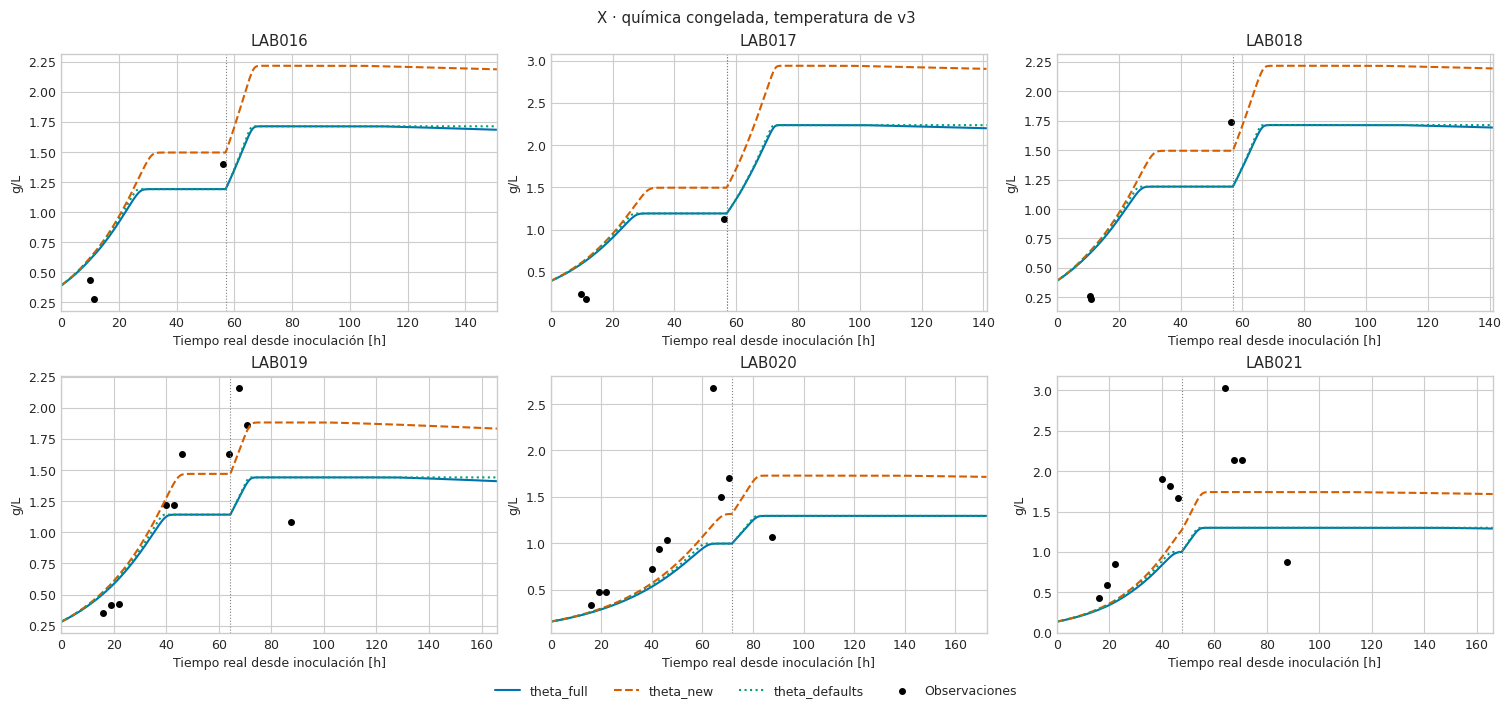

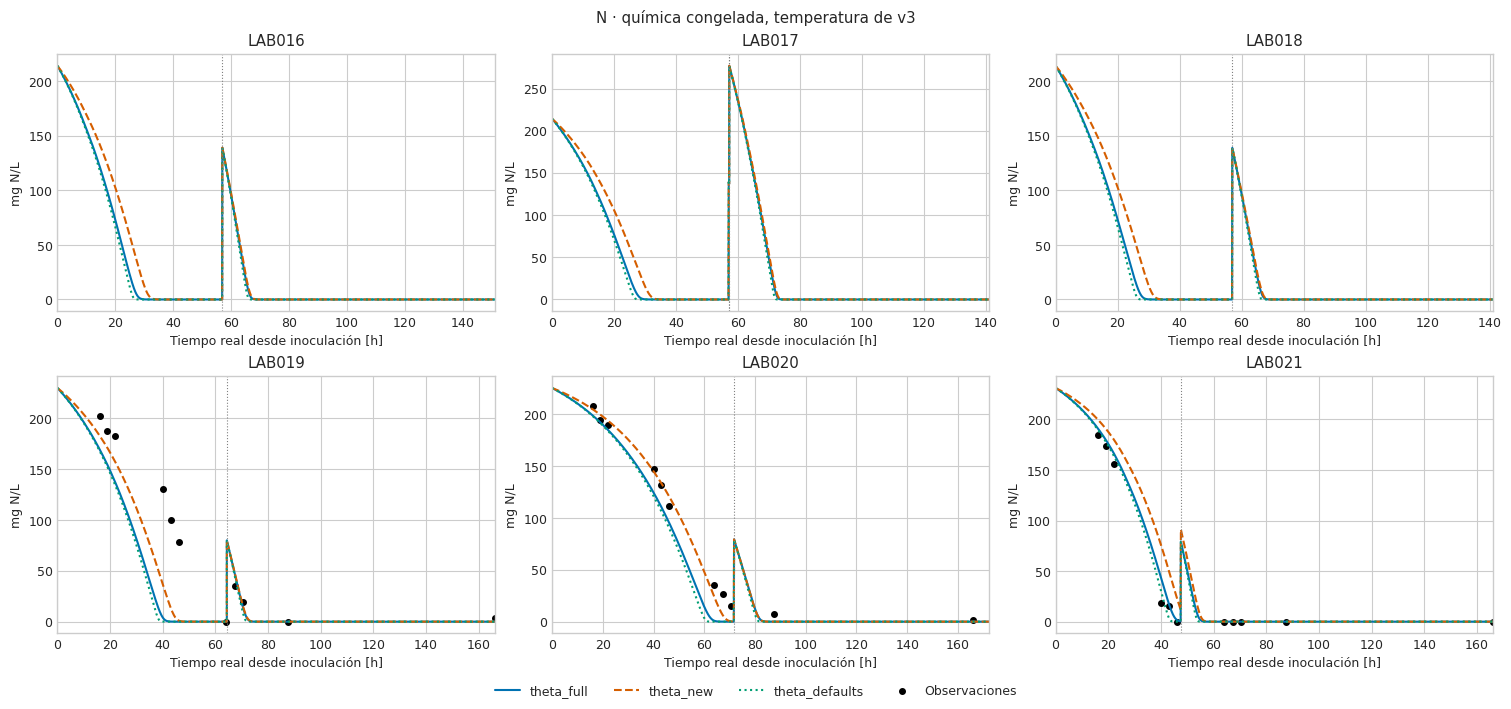

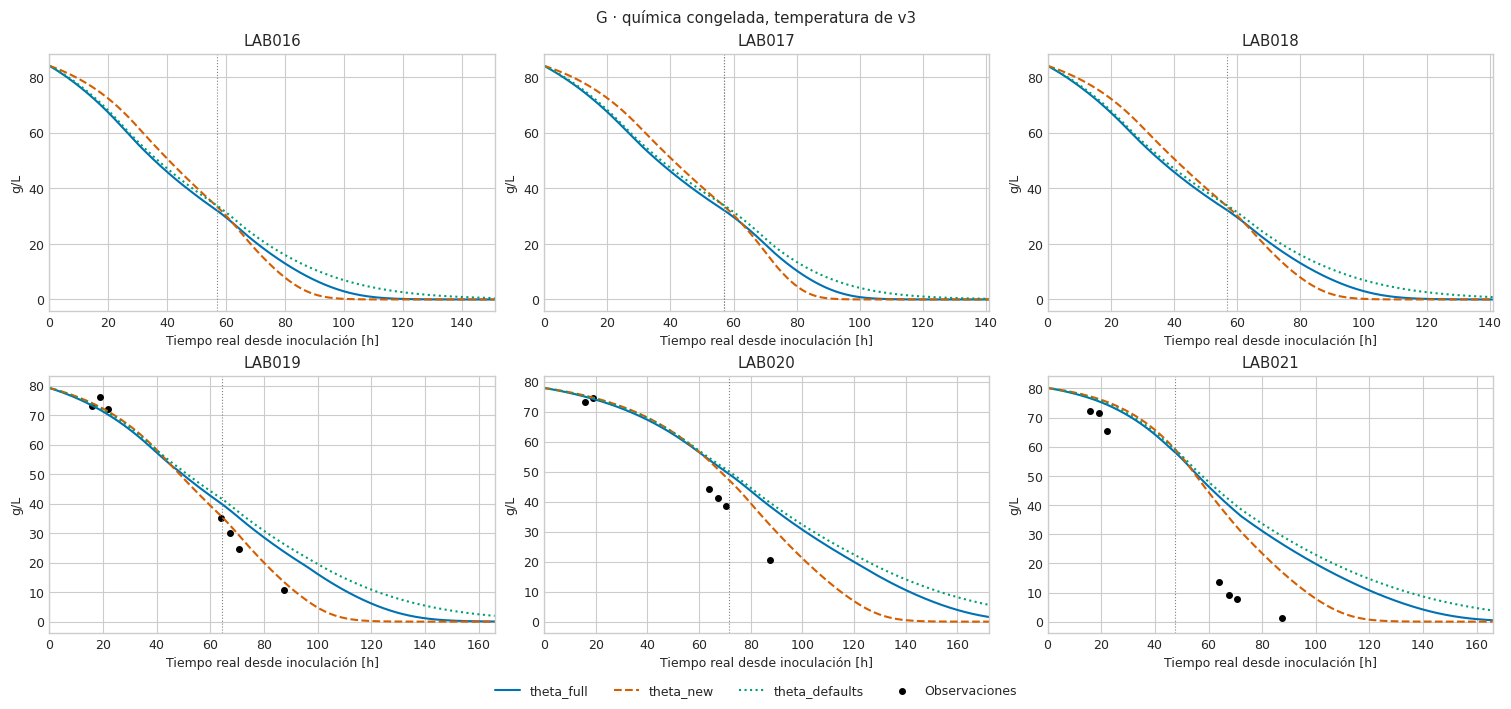

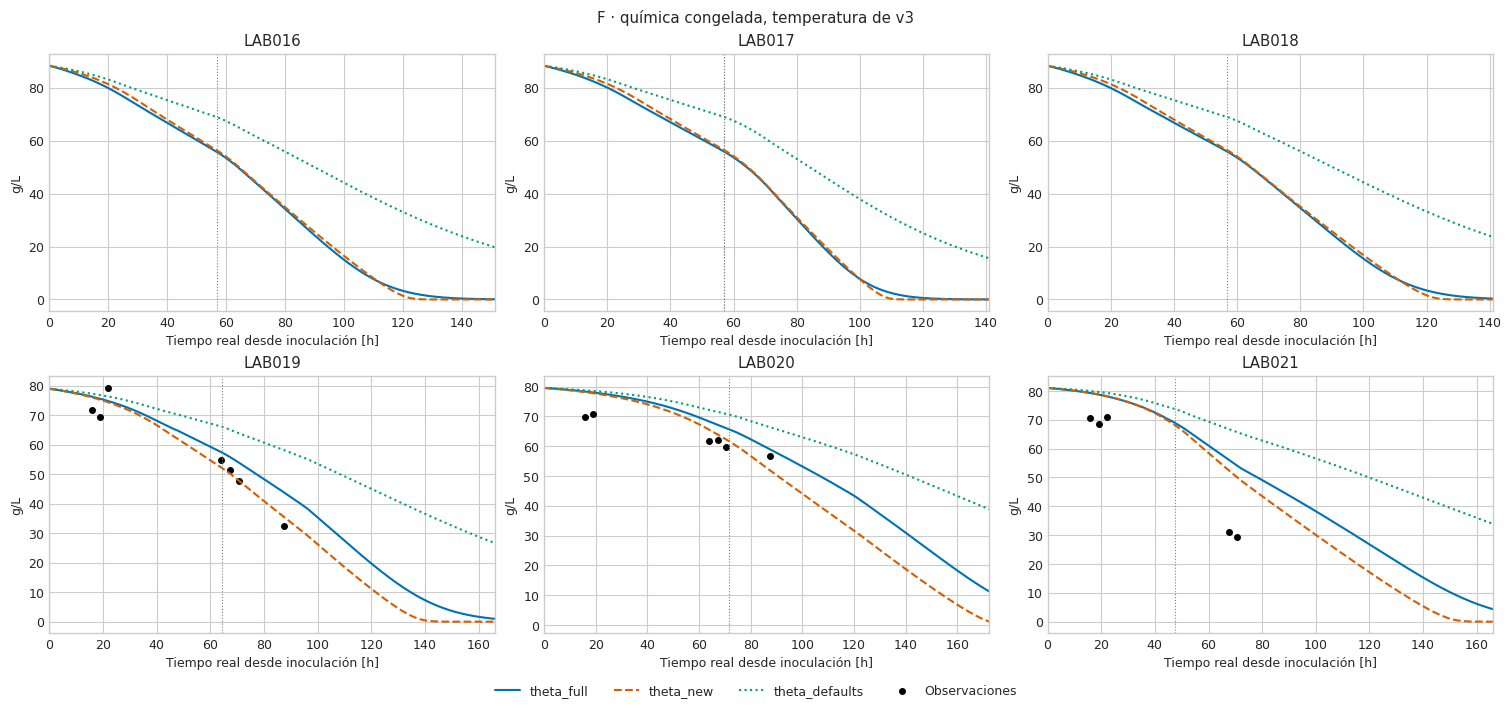

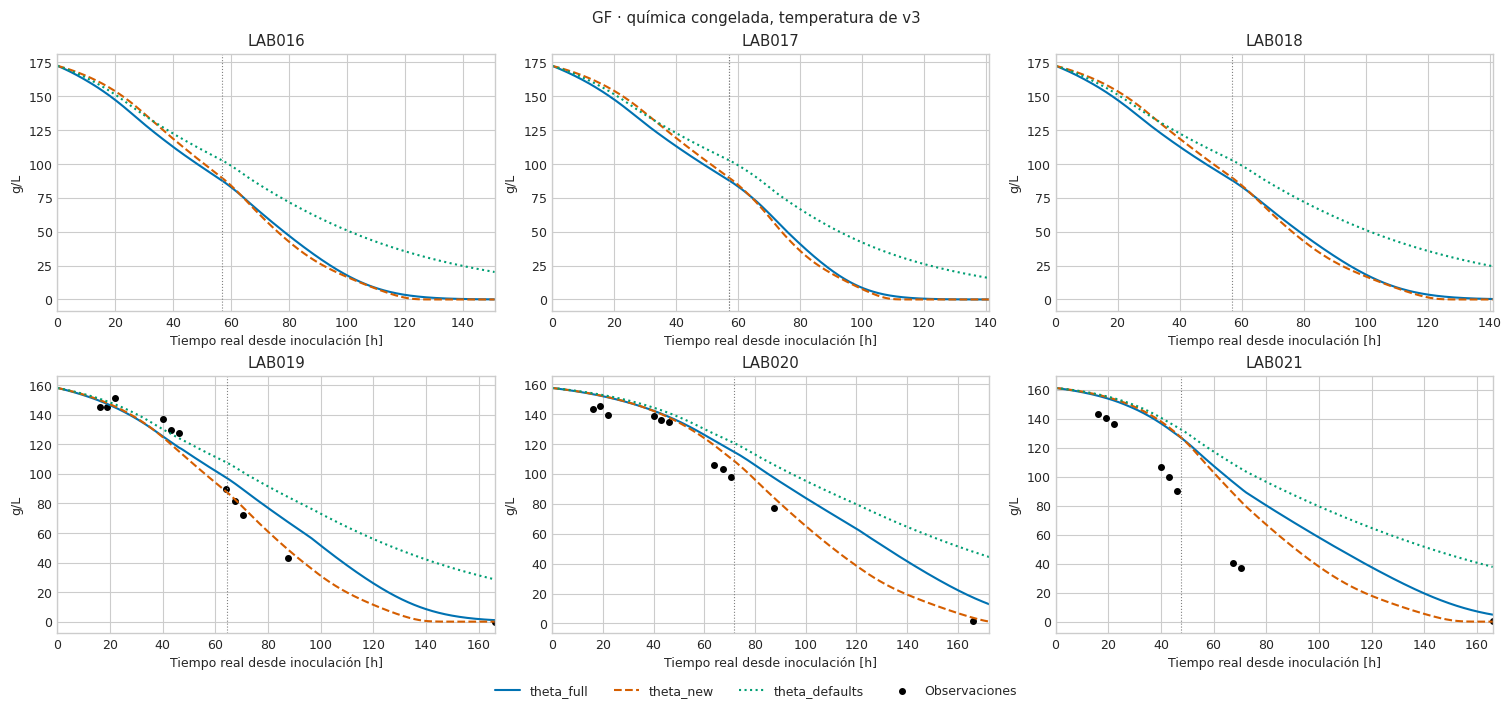

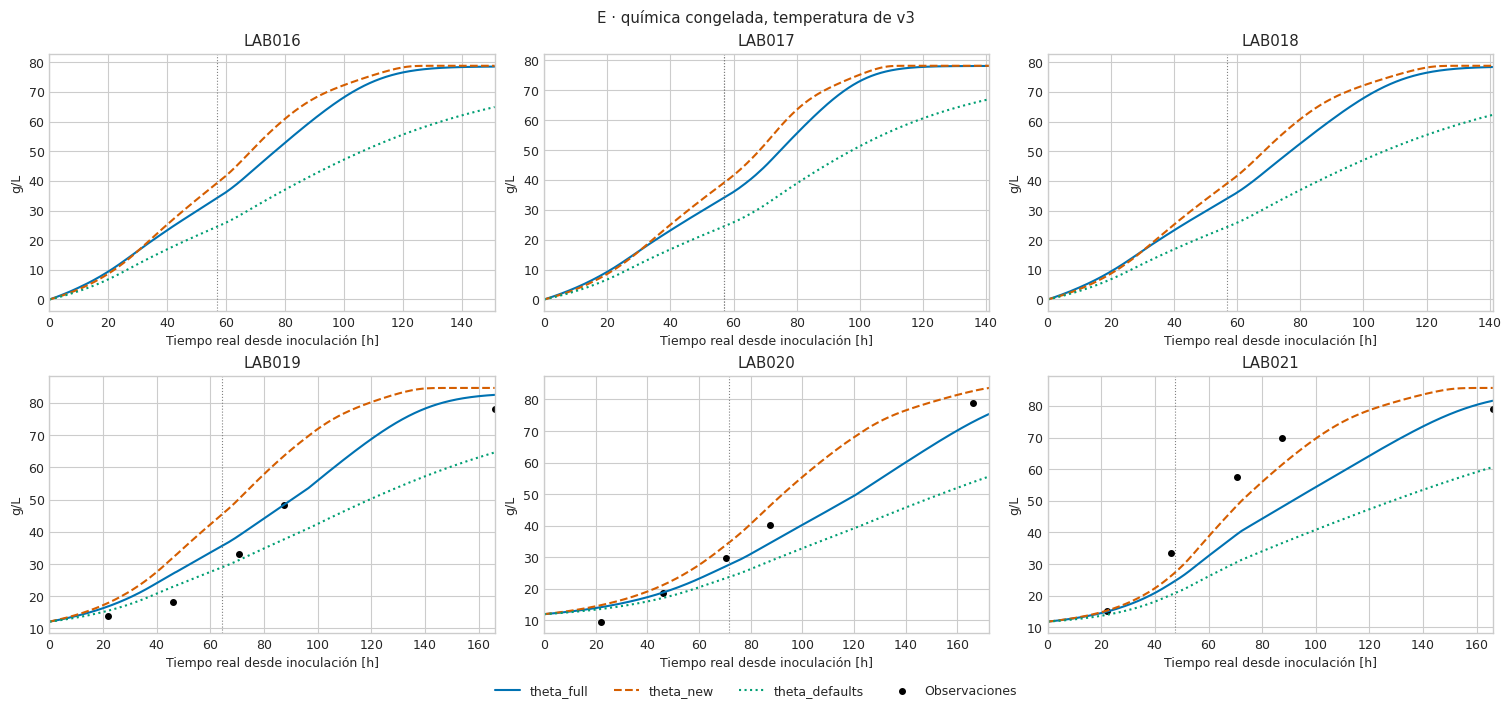

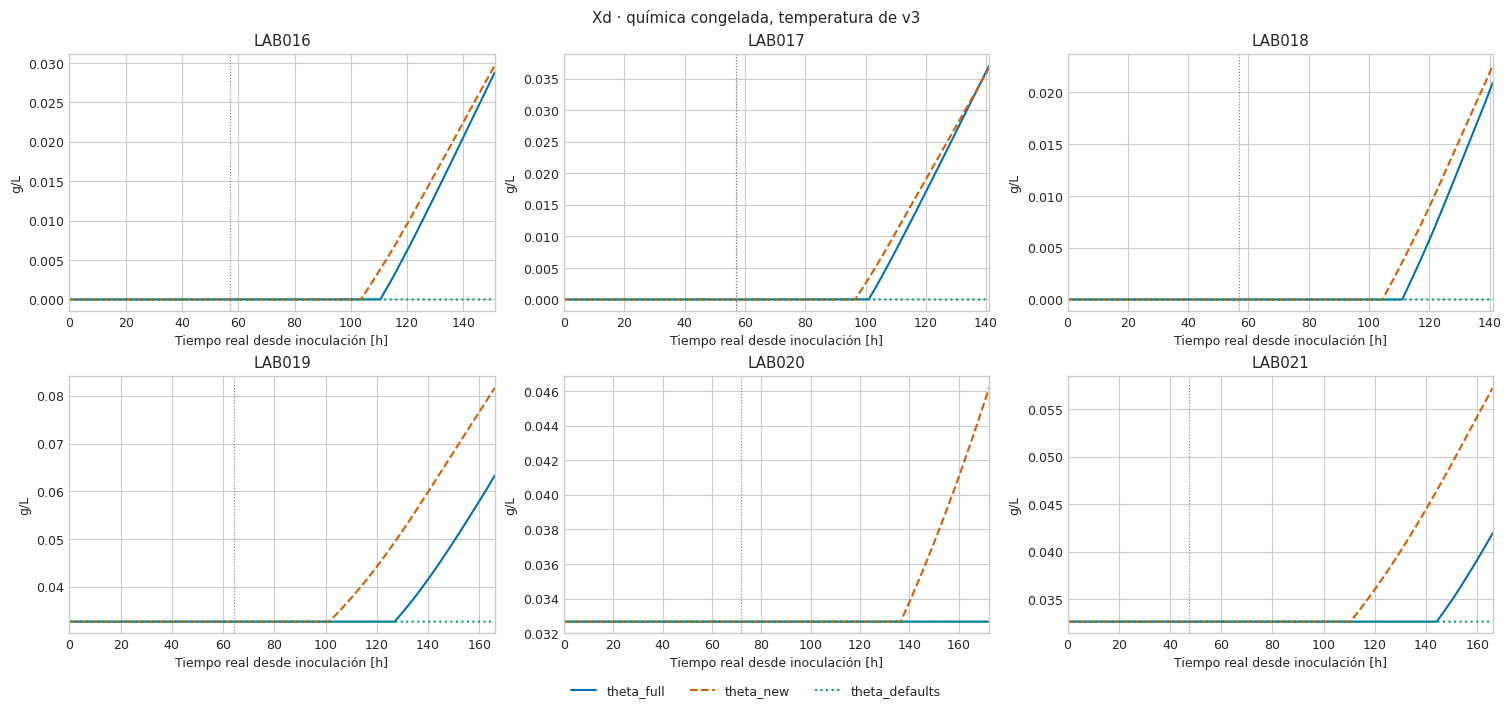

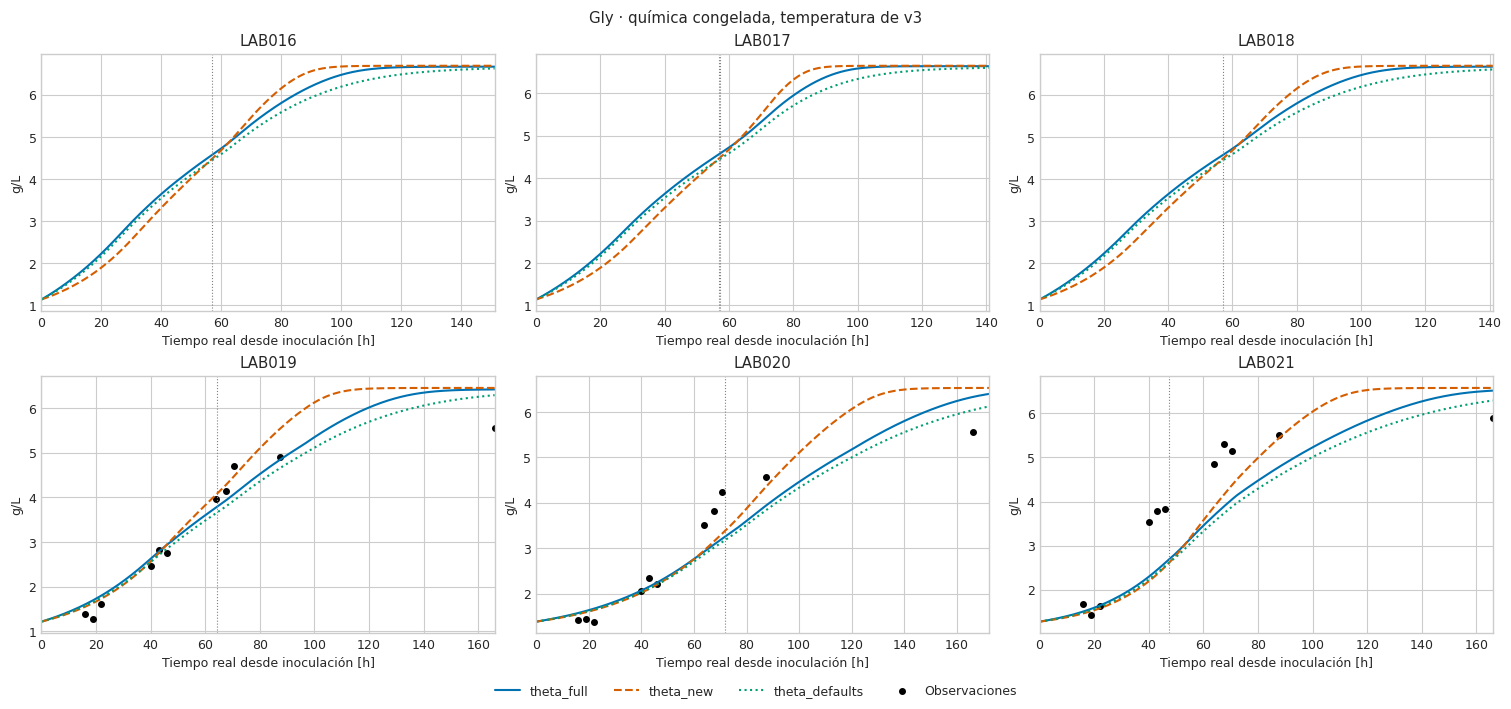

In [7]:
chem_columns={'X':'X_viable_g_l','N':'YAN_mg_l','G':'G_g_l','F':'F_g_l','GF':'GF_g_l','E':'E_g_l','Gly':'Gly_g_l'}
for state in ('X','N','G','F','GF','E','Xd','Gly'):
    fig,axes=plt.subplots(2,3,figsize=(15,7),layout='constrained')
    for ax,lab in zip(axes.flat,LABS):
        for case in CASES:
            cr=V.cores[case,lab];keep=cr.index<=V.horizons[lab]
            ax.plot(cr.index[keep],cr.loc[keep,state]*(1000. if state=='N' else 1.),color=COLORS[case],linestyle=STYLES[case],label=case)
        col=chem_columns.get(state)
        if lab in TRAIN and col and col in V.chem:
            pts=V.chem[V.chem.lab.eq(lab)&~V.chem.is_NUT&V.chem.t_h.gt(0.)].dropna(subset=[col])
            ax.scatter(pts.t_h,pts[col],s=16,color='black',label='Observaciones')
        elif state=='X' and lab in HOLDOUT:
            pts=V.biomass[V.biomass.lab.eq(lab)]
            ax.scatter(pts.t_h,pts.X_viable_g_l,s=16,color='black',label='Observaciones')
        for event,dose in V.batches[lab].pulses['N']:ax.axvline(event,color='.5',linestyle=':',linewidth=.8)
        ax.set_title(lab);ax.set_xlim(0,V.horizons[lab]);ax.set_xlabel('Tiempo real desde inoculación [h]');ax.set_ylabel('mg N/L' if state=='N' else 'g/L')
    fig.suptitle(state+' · química congelada, temperatura de v3')
    handles,labels=axes.flat[-1].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=4)
    display(fig);plt.close(fig)


## 7. Ajustes Z1/Z2 de la capa, con los tres theta congelados

In [8]:
GROUPS={'all_six':LABS,'train_019_021':LABS[3:],'train_016_018':LABS[:3]}
for case in CASES:
    for label,training in GROUPS.items():
        V.fit_layer(case,training,label,starts=3,max_nfev=180)
        pd.DataFrame(V.fit_table).to_csv(OUT/'fit_parameters.csv',index=False)
        pd.DataFrame(V.fit_runs).to_csv(OUT/'optimizer_runs.csv',index=False)
FIT_TABLE=pd.DataFrame(V.fit_table)
display(FIT_TABLE.round(6))
main_metrics=[];main_curves=[]
for case in CASES:
    for training in GROUPS:
        for stage in ('Z1','Z2'):
            params=V.v3_fits[('reference_20_45',PRIMARY,'v2',case,training,stage)]
            main_metrics.append(V.metrics_v3(case,params,LABS).assign(training=training,stage=stage))
            for lab in LABS:
                cr=V.curve_v3(case,lab,params)
                main_curves.append(cr[cr.t_h<=V.horizons[lab]+1e-8].assign(lab=lab,theta=case,training=training,stage=stage))
METRICS=pd.concat(main_metrics,ignore_index=True)
METRICS['role']=['calibration' if row.training=='all_six' or row.lab in GROUPS[row.training] else 'transfer' for row in METRICS.itertuples()]
METRICS.to_csv(OUT/'metrics.csv',index=False)
pd.concat(main_curves,ignore_index=True).to_csv(OUT/'gas_trajectories.csv',index=False)
display(METRICS.query('window == "all"').groupby(['theta','training','stage','role']).RMSE.mean().to_frame().round(6))

# Frozen-parameter parity is checked separately. A local refit can settle at a
# different numerical minimum, so report its difference instead of claiming
# identical recalibration parameters.
historical_fit=reference_fits.query('temperature == "reference_20_45" and filtering == @PRIMARY and mode == "v2"')
refit_comparison=FIT_TABLE[['theta','training','stage','objective',*GAS_NAMES]].merge(
    historical_fit[['theta','training','stage','objective',*GAS_NAMES]],
    on=['theta','training','stage'],how='left',suffixes=('_new','_archived'),validate='one_to_one')
refit_comparison['objective_relative_change_pct']=100.*(
    refit_comparison.objective_new/refit_comparison.objective_archived-1.)
refit_comparison.to_csv(OUT/'refit_vs_archived.csv',index=False)
display(refit_comparison[['theta','training','stage','objective_new','objective_archived','objective_relative_change_pct']].round(7))
display(Markdown('La equivalencia del traslado se verifica con parámetros congelados. Los reajustes locales Z1/Z2 se muestran por separado y pueden terminar en mínimos numéricos distintos; no se afirma unicidad ni óptimo global. theta_new no tiene una calibración v3 archivada de referencia.'))


reference_20_45 offline_30min v2 theta_full all_six Z1/Z2 0.12011 0.107222


reference_20_45 offline_30min v2 theta_full train_019_021 Z1/Z2 0.055775 0.053997


reference_20_45 offline_30min v2 theta_full train_016_018 Z1/Z2 0.059046 0.034594


reference_20_45 offline_30min v2 theta_new all_six Z1/Z2 0.089499 0.070326


reference_20_45 offline_30min v2 theta_new train_019_021 Z1/Z2 0.046521 0.046046


...

reference_20_45 offline_30min v2 theta_defaults train_016_018 Z1/Z2 0.064204 0.044198


,temperature,filtering,mode,theta,training,labs,stage,success,objective,jacobian_ratio,active_bounds,kCO2_release_h,CO2sat_scale,matrix_gain
0,reference_20_45,offline_30min,v2,theta_full,all_six,"LAB016,LAB017,LAB018,LAB019,LAB020,LAB021",Z1,True,0.120110,NaN,,0.424588,0.351390,0.924954
1,reference_20_45,offline_30min,v2,theta_full,all_six,"LAB016,LAB017,LAB018,LAB019,LAB020,LAB021",Z2,True,0.107222,0.000390,,0.167019,1.289741,0.953991
2,reference_20_45,offline_30min,v2,theta_full,train_019_021,"LAB019,LAB020,LAB021",Z1,True,0.055775,NaN,,0.424588,0.351390,1.055119
3,reference_20_45,offline_30min,v2,theta_full,train_019_021,"LAB019,LAB020,LAB021",Z2,True,0.053997,0.000215,,2.000835,0.999955,1.054708
4,reference_20_45,offline_30min,v2,theta_full,train_016_018,"LAB016,LAB017,LAB018",Z1,True,0.059046,NaN,,0.424588,0.351390,0.880749
5,reference_20_45,offline_30min,v2,theta_full,train_016_018,"LAB016,LAB017,LAB018",Z2,True,0.034594,0.014447,CO2sat_scale,0.148732,2.500000,0.935727
6,reference_20_45,offline_30min,v2,theta_new,all_six,"LAB016,LAB017,LAB018,LAB019,LAB020,LAB021",Z1,True,0.089499,NaN,,0.424588,0.351390,0.784255
7,reference_20_45,offline_30min,v2,theta_new,all_six,"LAB016,LAB017,LAB018,LAB019,LAB020,LAB021",Z2,True,0.070326,0.000601,CO2sat_scale,0.190736,2.500000,0.815824
8,reference_20_45,offline_30min,v2,theta_new,train_019_021,"LAB019,LAB020,LAB021",Z1,True,0.046521,NaN,,0.424588,0.351390,0.794513
9,reference_20_45,offline_30min,v2,theta_new,train_019_021,"LAB019,LAB020,LAB021",Z2,True,0.046046,0.001295,,0.720807,2.402843,0.797952


RMSE
theta          training      stage role                 
theta_defaults all_six       Z1    calibration  0.145493
                             Z2    calibration  0.136640
               train_016_018 Z1    calibration  0.146814
                                   transfer     0.145967
                             Z2    calibration  0.121601
                                   transfer     0.151564
               train_019_021 Z1    calibration  0.139289
                                   transfer     0.175431
                             Z2    calibration  0.139679
                                   transfer     0.188093
theta_full     all_six       Z1    calibration  0.139864
                             Z2    calibration  0.128523
               train_016_018 Z1    calibration  0.140754
                                   transfer     0.140519
                             Z2    calibration  0.107421
                                   transfer     0.149974
               train_019_021 Z1    calibration  0.135207
                                   transfer     0.163440
                             Z2    calibration  0.134208
                                   transfer     0.178257
theta_new      all_six       Z1    calibration  0.116764
                             Z2    calibration  0.093914
               train_016_018 Z1    calibration  0.119683
                                   transfer     0.113720
                             Z2    calibration  0.071071
                                   transfer     0.115652
               train_019_021 Z1    calibration  0.114213
                                   transfer     0.119884
                             Z2    calibration  0.112965
                                   transfer     0.118432

,theta,training,stage,objective_new,objective_archived,objective_relative_change_pct
0,theta_full,all_six,Z1,0.120110,0.120110,0.000000
1,theta_full,all_six,Z2,0.107222,0.106602,0.582044
2,theta_full,train_019_021,Z1,0.055775,0.055775,0.000000
3,theta_full,train_019_021,Z2,0.053997,0.053997,0.000000
4,theta_full,train_016_018,Z1,0.059046,0.059046,0.000000
5,theta_full,train_016_018,Z2,0.034594,0.034594,0.000000
6,theta_new,all_six,Z1,0.089499,NaN,NaN
7,theta_new,all_six,Z2,0.070326,NaN,NaN
8,theta_new,train_019_021,Z1,0.046521,NaN,NaN
9,theta_new,train_019_021,Z2,0.046046,NaN,NaN


La equivalencia del traslado se verifica con parámetros congelados. Los reajustes locales Z1/Z2 se muestran por separado y pueden terminar en mínimos numéricos distintos; no se afirma unicidad ni óptimo global. theta_new no tiene una calibración v3 archivada de referencia.

## 8. Curvas de CO₂: entrenamiento y transferencia, sin cambiar la fuente

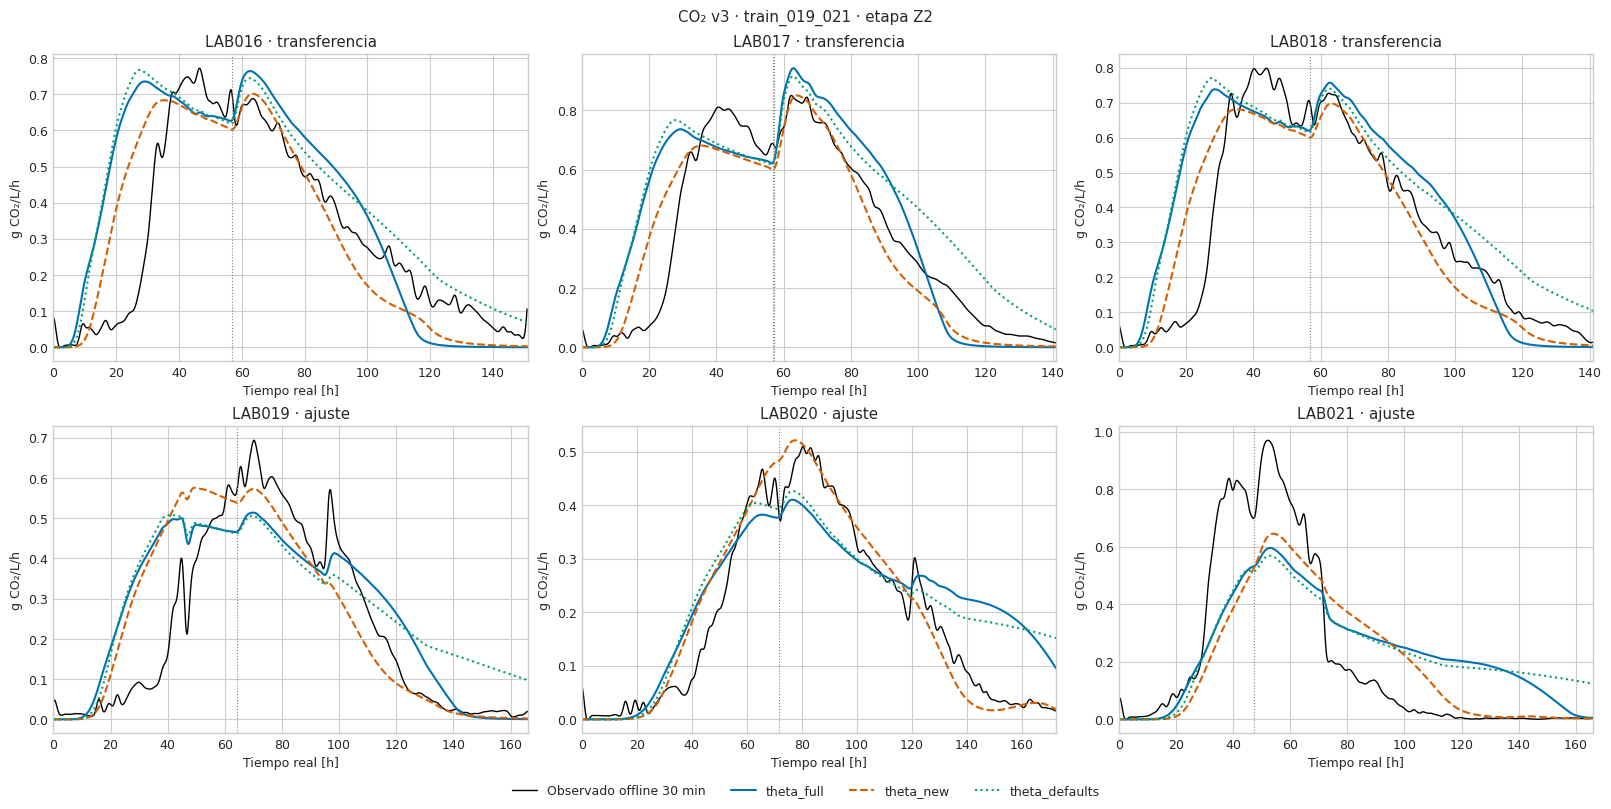

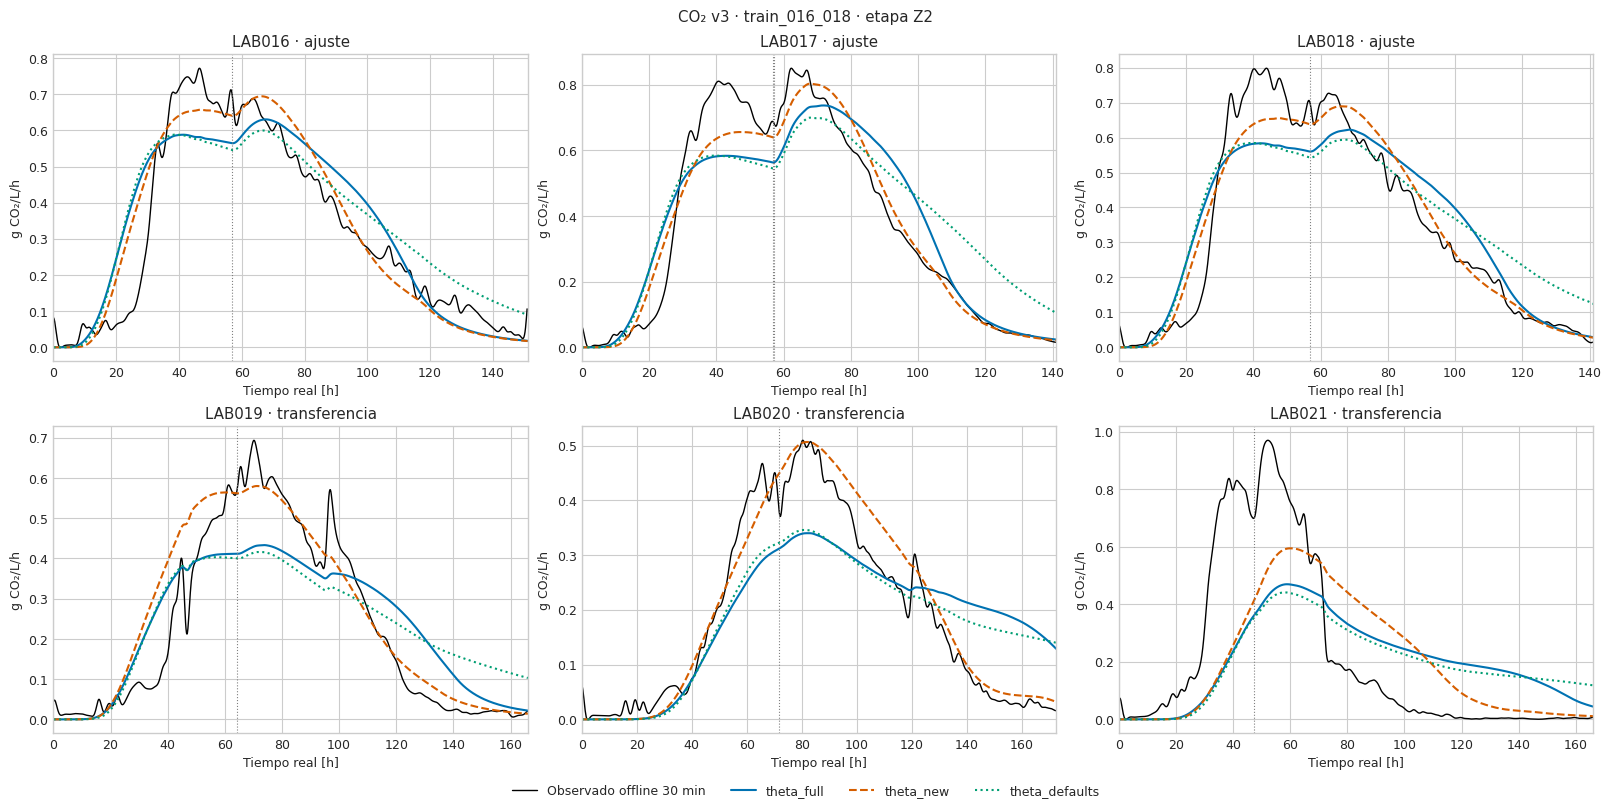

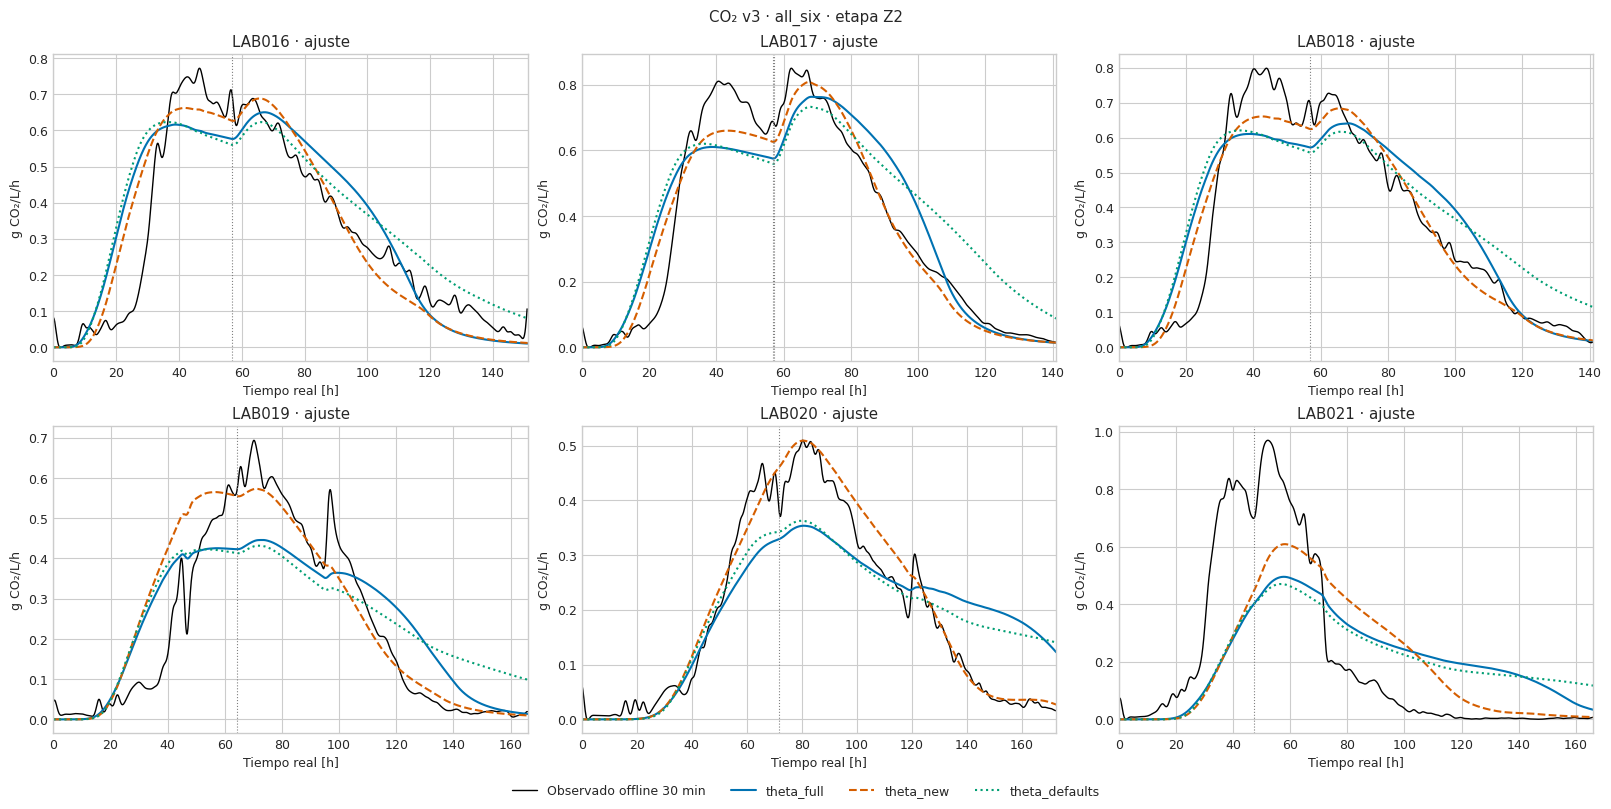

In [9]:
for training in ('train_019_021','train_016_018','all_six'):
    fig,axes=plt.subplots(2,3,figsize=(16,8),layout='constrained')
    for ax,lab in zip(axes.flat,LABS):
        obs=V.observations[PRIMARY,lab]
        ax.plot(obs.t_h,obs.y,color='black',linewidth=1.,label='Observado offline 30 min')
        for case in CASES:
            params=V.v3_fits[('reference_20_45',PRIMARY,'v2',case,training,'Z2')]
            cr=V.curve_v3(case,lab,params)
            ax.plot(cr.t_h,cr.CO2_observed_operator,color=COLORS[case],linestyle=STYLES[case],label=case)
        for event,dose in V.batches[lab].pulses['N']:ax.axvline(event,color='.5',linestyle=':',linewidth=.8)
        role='ajuste' if lab in GROUPS[training] else 'transferencia'
        ax.set_title(f'{lab} · {role}');ax.set_xlim(0,V.horizons[lab]);ax.set_xlabel('Tiempo real [h]');ax.set_ylabel('g CO₂/L/h')
    fig.suptitle('CO₂ v3 · '+training+' · etapa Z2')
    handles,labels=axes.flat[0].get_legend_handles_labels();fig.legend(handles,labels,loc='outside lower center',ncol=4)
    display(fig);plt.close(fig)


## 9. Conservación y comprobación numérica

In [10]:
checks=[]
for case in CASES:
    params=V.v3_fits[('reference_20_45',PRIMARY,'v2',case,'train_019_021','Z2')]
    for lab in LABS:
        cache=V.source_cache(case,lab,params,'v2')
        observed,physical,cd,qout=V.observed_prediction(case,lab,params)
        balance=float(np.max(abs(np.diff(cd)-cache['dt']*(cache['source'][:-1]-qout[1:]))))
        core=V.cores[case,lab];theta=V.theta_by_case[case]
        dose=np.array([sum(d for t,d in cache['events'] if t<ti) for ti in cache['time']])
        inventory=core.N+theta['qN']/theta['mu0']*(core.X+core.Xd)-dose
        nitrogen=float(np.max(abs(inventory-inventory.iloc[0])))
        fine=V.observed_prediction(case,lab,params,max_step=1./48.)[0]
        obs=V.observations[PRIMARY,lab];t=V.dense[lab].time_h.to_numpy()
        coarse_sample=np.interp(obs.t_h,t,observed);fine_sample=np.interp(obs.t_h,t,fine)
        refinement=float(np.max(abs(coarse_sample-fine_sample)))
        assert balance<1e-10 and nitrogen<2e-6
        assert min(np.min(cd),np.min(physical),np.min(cache['source']))>=-1e-12
        assert refinement<.025,(case,lab,refinement)
        checks.append(dict(theta=case,lab=lab,CO2_balance=balance,nitrogen_inventory=nitrogen,reservoir_refinement_max=refinement))
display(pd.DataFrame(checks));pd.DataFrame(checks).to_csv(OUT/'numerical_checks.csv',index=False)
assert FIT_TABLE.success.all(),FIT_TABLE.loc[~FIT_TABLE.success]
assert V.verify_protected()>0
TRACE.update({'preprocessing_max_abs':preprocess_error,'time_max_abs':time_error,
    'frozen_gas_max_abs':float(frozen_parity.select_dtypes('number').to_numpy().max()),
    'core_max_abs':max(row['chemical_max_abs'] for row in parity),'states':list(base.STATE_NAMES),
    'gas_equation_mode':'v2 as in v3 primary','oxygen_retained':True,'chemical_theta_refitted':False,
    'gas_parameters_Z1':['matrix_gain'],'gas_parameters_Z2':list(GAS_NAMES),
    'elapsed_s':time.perf_counter()-START})
display(JSON(TRACE,expanded=False))
display(Markdown('La paridad con los datos y las curvas archivadas comprueba la migración. Los reajustes Z1/Z2 son ensayos de compatibilidad de la capa histórica; no seleccionan una formulación nueva ni validan sus mecanismos. all_six es descriptivo; las transferencias se muestran separadas de los ajustes.'))


,theta,lab,CO2_balance,nitrogen_inventory,reservoir_refinement_max
0,theta_full,LAB016,6.192150e-17,2.386980e-15,0.000651
1,theta_full,LAB017,1.146002e-16,9.658940e-15,0.001318
2,theta_full,LAB018,6.201636e-17,2.109424e-15,0.000643
3,theta_full,LAB019,6.028164e-17,5.051515e-15,0.000733
4,theta_full,LAB020,5.846221e-17,1.443290e-15,0.000189
5,theta_full,LAB021,6.169110e-17,1.998401e-15,0.000402
6,theta_new,LAB016,2.320193e-16,3.663736e-15,0.000617
7,theta_new,LAB017,2.283330e-16,5.995204e-15,0.001268
8,theta_new,LAB018,2.299593e-16,3.386180e-15,0.000611
9,theta_new,LAB019,2.272488e-16,4.052314e-15,0.000340


<IPython.core.display.JSON object>

La paridad con los datos y las curvas archivadas comprueba la migración. Los reajustes Z1/Z2 son ensayos de compatibilidad de la capa histórica; no seleccionan una formulación nueva ni validan sus mecanismos. all_six es descriptivo; las transferencias se muestran separadas de los ajustes.